# 
Notebook 04: Order Profitability Prediction Pipeline
**Project**: E-Commerce Discount Impact Analysis  
**Stage**: Leakage-Free Feature Engineering, Chronological Split, Benchmark Models & Explainability

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.train_model import (
    prepare_ml_dataset,
    time_based_train_test_split,
    train_and_evaluate_all_models,
    extract_feature_importances,
    plot_model_evaluation
)

orders_df = pd.read_csv('data/processed/orders_delivered_aggregated.csv')
orders_df['OrderDate'] = pd.to_datetime(orders_df['OrderDate'])

### 1. Leakage-Free Feature Extraction & Chronological Splitting

In [2]:
X, y, df = prepare_ml_dataset(orders_df)
split_data = time_based_train_test_split(X, y, df, train_ratio=0.8)

print(f"Train Period: {split_data['train_period']} (n={split_data['train_size']:,})")
print(f"Test Period:  {split_data['test_period']} (n={split_data['test_size']:,})")

Train Period: 2024-01-01 to 2026-01-30 (n=3,508)
Test Period:  2026-01-30 to 2026-07-31 (n=878)


### 2. Model Training & Cross-Validation Benchmarking

In [3]:
model_output = train_and_evaluate_all_models(split_data)
eval_df = pd.DataFrame([
    {
        'Model': name,
        'CV R²': f"{m['CV_R2']:.4f}",
        'Test MAE': f"${m['Test_MAE']:,.2f}",
        'Test RMSE': f"${m['Test_RMSE']:,.2f}",
        'Test R²': f"{m['Test_R2']:.4f}"
    }
    for name, m in model_output['metrics'].items()
]).set_index('Model')

display(eval_df)

,CV R²,Test MAE,Test RMSE,Test R²
Model,,,,
Baseline (Mean),0.0000,"$7,537.94","$9,498.51",-0.0000
Ridge Regression,0.8899,"$2,157.05","$2,843.05",0.9104
Random Forest,0.8865,"$1,989.28","$2,758.30",0.9157
Gradient Boosting,0.8901,"$2,005.16","$2,736.71",0.9170


### 3. Feature Importance & Model Diagnostics

,Feature,Importance
0,order_value,0.940539
1,total_quantity,0.023265
2,avg_discount,0.016633
3,max_discount,0.004941
4,CustomerTenureDays,0.003235
5,Age,0.002514
6,Books,0.002083
7,Home,0.001889


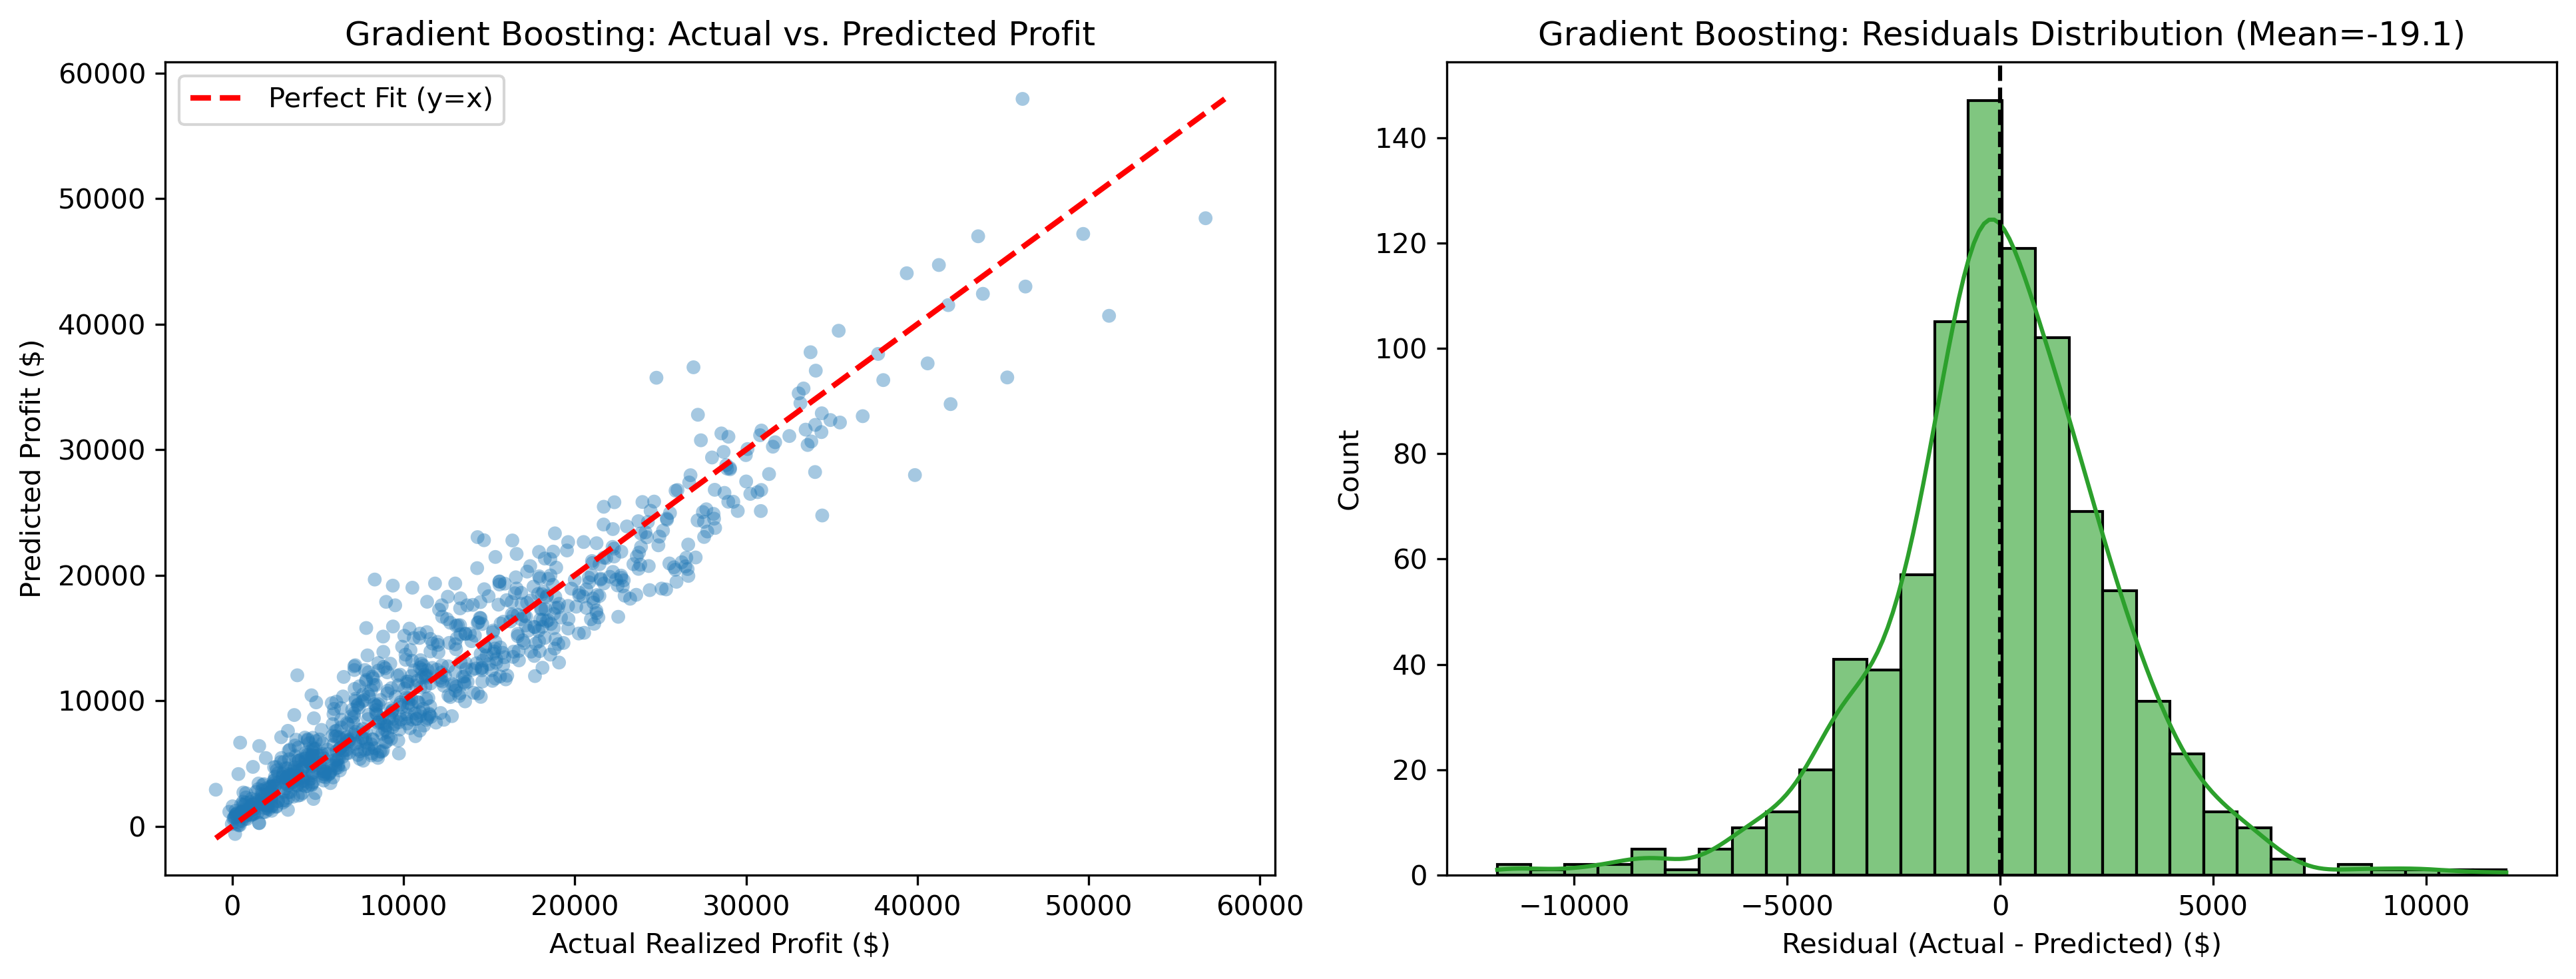

In [4]:
gb_model = model_output['models']['Gradient Boosting']
feat_imp = extract_feature_importances(gb_model, split_data['X_train'].columns)
display(feat_imp.head(8))

fig = plot_model_evaluation(gb_model, split_data['X_test'], split_data['y_test'])
plt.show()